# FILTRO DE KALMAN PARA ESTIMAR UN PARÁMETRO DESCONOCIDO
En este ejemplo se estima un parámetro constante $a$ de un sistema:

$z(k) = a \cdot u(k) + v(k)$

donde:

$u(k)$: señal de entrada conocida

$z(k)$: salida - medición ruidosa

$a$: parámetro desconocido (constante)

$v(k)$: ruido de medición

El filtro de Kalman se utiliza tratando el parámetro como un estado:

$a(k+1) = a(k) + w(k)$

donde $w(k)$ es el ruido del proceso

In [11]:
import numpy as np

# Configuración de la simulación
T = 10  # Tiempo de simulación
dt = 0.1 # Periodo de muestreo
sigma_v = 0.5 # desv. stand. ruido de medición
sigma_w = 1e-3 # desv. stand. de sistema
# Valor real del parámetro
a_real = 2.75

Se realiza la simulacion para obtener datos

In [12]:
t = np.arange(0,T,dt)
u = np.sin(2*t) + 0.2*np.random.randn(len(t)) # Entrada conocida
v = sigma_v * np.random.randn(len(t)) # Ruido de medición
z = a_real * u + v # mediciones ruidosas

Inicialización de los parámtros del filtro de Kalman

In [13]:
x_est = 0 # Estimación inicial del parámetro
P = 10 # Estimación de covarianza inicial
F = 1 # Matriz de transición

Q = sigma_w**2 # Coavarianza del ruido de proceso
R = sigma_v**2 # Covarianza del ruido de medición

# Almacenamiento de datos
x_t = np.zeros(len(t))
P_t = np.zeros(len(t))
K_t = np.zeros(len(t))

## FILTRO DE KALMAN

In [14]:
for k in range(len(t)):

    # Predicción
    x_pred = F * x_est
    P_pred = F*P*F + Q

    # Actualización
    # Modelo de medición z(k) = H*x + v
    H = u[k]
    y_m = z[k] - H * x_pred

    # Ganancia de Kalman
    S = H*P_pred*H + R
    K = P_pred * H / S

    # Corrección
    x_est = x_pred + K * y_m

    # Actualización de covarianza
    P = (1 - K*H) * P_pred

    # Guardar reultados
    x_t[k] = x_est
    P_t[k] = P
    K_t[k] = K

Resultados y evaluación

Valor real del parámetro:  2.75
Estiamción final:  2.6946670929632606
Error absoluto:  0.05533290703673943


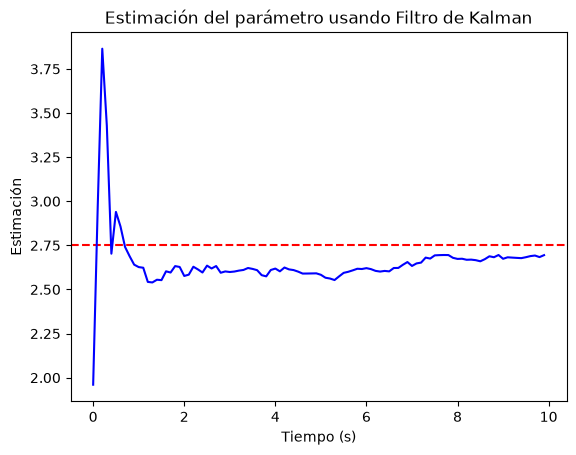

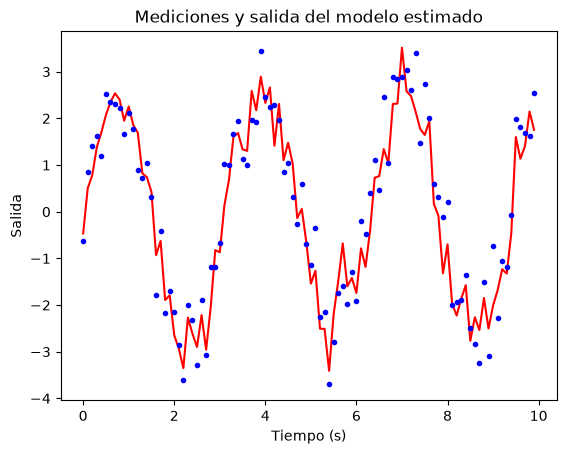

In [15]:
import matplotlib.pyplot as plt

print("Valor real del parámetro: ", a_real)
print("Estiamción final: ", x_est)
print("Error absoluto: ", np.abs(a_real-x_est))

# Graficas
plt.figure(1)
plt.axhline( a_real, color = 'r', linestyle='--')
plt.plot(t,x_t, color='b')
plt.title("Estimación del parámetro usando Filtro de Kalman")
plt.xlabel("Tiempo (s)")
plt.ylabel("Estimación")

# Modelo estimado
z_est = x_est * u
plt.figure(2)
plt.plot(t, z_est, color='r')
plt.plot(t, z, '.', color='b')
plt.xlabel("Tiempo (s)")
plt.ylabel("Salida")
plt.title("Mediciones y salida del modelo estimado")

plt.show()